# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 1: Load Data & EDA

Dataset: *Emotion Dataset from Indonesian Public Opinion* (Riccosan dkk., 2022), terdiri dari **6 file terpisah** (satu file per kelas emosi), dipisahkan dengan "TAB".
Notebook ini menggabungkan 6 file tersebut, memeriksa struktur, distribusi kelas, missing value, duplikat, dan panjang teks,
lalu menyimpan gabungan raw datanya ke `data/raw_combined.csv`

In [ ]:
import os
import csv
import pandas as pd
import matplotlib.pyplot as plt

# Folder lokal berisi 6 file CSV (AngerData.csv, FearData.csv, dst.)
BASE = "data/Emotion-Dataset-from-Indonesian-Public-Opinion"

OUT_RAW = "data/raw_combined.csv" # hasil gabungan 6 file
FIG_DIR = "outputs/figures" # folder untuk grafik

LABEL_FILES = {    # label diambil dari nama file
    "anger":   "AngerData.csv",
    "fear":    "FearData.csv",
    "joy":     "JoyData.csv",
    "love":    "LoveData.csv",
    "sad":     "SadData.csv",
    "neutral": "NeutralData.csv",
}
TEXT_COL, LABEL_COL = "text", "label" # nama kolom standar yang dipakai di semua notebook

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(os.path.dirname(OUT_RAW), exist_ok=True)
pd.set_option("display.max_colwidth", 120)

### Step 1 - Load 6 file dan gabungkan

In [ ]:
frames, info = [], []
for lab, fname in LABEL_FILES.items():
    # sep="\t" : file dipisah TAB, bukan koma
    # quoting=QUOTE_NONE : Wajib dilakukan, karena banyak tweet yang mengandung tanda kutip (")
    # yang tidak berpasangan. Secara default, pandas menganggapnya awal "field berkutip" dan
    # menelan beberapa baris tweet sekaligus menjadi 1 baris --> data rusak
    raw = pd.read_csv(f"{BASE}/{fname}", sep="\t", quoting=csv.QUOTE_NONE, encoding="utf-8")
    info.append({"file": fname, "baris": len(raw), "kolom_asli": list(raw.columns)})

    # Ambil 2 kolom terakhir (teks, label). Aman jika ada kolom indeks tambahan di depan
    part = raw.iloc[:, -2:].copy()
    part.columns = [TEXT_COL, "label_asli"]
    part["label_file"] = lab
    frames.append(part)

print("Ringkasan per file:")
display(pd.DataFrame(info))

df = pd.concat(frames, ignore_index=True)

# Label utama = label dari nama file. Mengecek apakah konsisten dengan kolom label di dalam file
df[LABEL_COL] = df["label_file"]
mismatch = (df["label_asli"].astype(str).str.strip().str.lower() != df[LABEL_COL]).sum()
print(f"\nTotal gabungan: {len(df)} baris | label di dalam file != label nama file: {mismatch} baris")
print("Catatan: jumlah ini = jumlah baris fisik di file (tanpa header). Paper dataset menyebut 7.080 teks; lihat sel berikutnya.")

Ringkasan per file:


,file,baris,kolom_asli
0,AngerData.csv,1135,"[Tweet, Label]"
1,FearData.csv,911,"[Tweet, Label]"
2,JoyData.csv,1275,"[Tweet, Label]"
3,LoveData.csv,760,"[Tweet, Label]"
4,SadData.csv,1022,"[Tweet, Label]"
5,NeutralData.csv,2002,"[Tweet, Label]"



Total gabungan: 7105 baris | label di dalam file != label nama file: 0 baris
Catatan: jumlah ini = jumlah baris fisik di file (tanpa header). Paper dataset menyebut 7.080 teks; lihat sel berikutnya.


In [ ]:
# Melakukan sanity check: apakah 1 baris DataFrame = 1 baris fisik di file?
# (membuktikan tidak ada tweet yang "tertelan")
n_fisik = 0
for fname in LABEL_FILES.values():
    with open(f"{BASE}/{fname}", encoding="utf-8") as f:
        n_fisik += sum(1 for _ in f) - 1 # dikurangi 1 baris header
print("Baris fisik di 6 file (tanpa header):", n_fisik)
print("Baris di DataFrame                  :", len(df))
assert n_fisik == len(df), "Jumlah tidak sama -> ada baris yang menyatu. Periksa parameter quoting."

# Tweet yang mengandung karakter kontrol / non-print (akan ditangani di Tahap 2)
n_ctrl = df[TEXT_COL].astype(str).str.contains(r"[\x00-\x08\x0b-\x1f\x7f-\x9f]", regex=True).sum()
print("Tweet mengandung karakter kontrol   :", n_ctrl)

Baris fisik di 6 file (tanpa header): 7105
Baris di DataFrame                  : 7105
Tweet mengandung karakter kontrol   : 81


In [ ]:
print("Nama kolom:", df.columns.tolist())
print(df.dtypes)
df[[TEXT_COL, LABEL_COL]].sample(8, random_state=42)

Nama kolom: ['text', 'label_asli', 'label_file', 'label']
text          object
label_asli    object
label_file    object
label         object
dtype: object


,text,label
6421,"bolos, katanya takut kena congorna",neutral
5681,"lima menit pun, setidak deras apapun hujan, tatap saja basah; yang kemudian bisa hadirkan sakit apabila kondisi bada...",neutral
4678,"pantes yh waktu hari kamis wajah ell tuh kek lemas trs matanya berkaca kaca w kira lagi sedih, tp w kalau sakit suka...",sad
4834,aku dari minggu lalu pengen ke pantai and tempat yang dingin dingin gitu kaya bukit tapi gak kesampaian,sad
5652,"tentu saja kalo jual cash, ga dapet r",neutral
4955,ga enak bgt bangun bangun badan panass:(,sad
2413,yaudah semangat,joy
318,tp lebih tolol fenss nya sih,anger


In [ ]:
# Simpan gabungan raw data (belum dibersihkan apa pun) untuk Tahap 2
df[[TEXT_COL, LABEL_COL]].to_csv(OUT_RAW, index=False)
print("Tersimpan:", OUT_RAW)

Tersimpan: data/raw_combined.csv


## Step 2 - Menangani missing value

In [ ]:
missing = df[[TEXT_COL, LABEL_COL]].isna().sum().to_frame("jumlah_NaN")
n_blank = (df[TEXT_COL].fillna("").astype(str).str.strip() == "").sum()   # "" atau hanya spasi
missing.loc["teks_kosong_atau_spasi"] = n_blank
missing

,jumlah_NaN
text,0
label,0
teks_kosong_atau_spasi,0


## Step 3 - Jumlah data per kelas

In [ ]:
dist = (df[LABEL_COL].value_counts(dropna=False)
          .rename_axis("label").reset_index(name="jumlah"))
dist["persen (%)"] = (dist["jumlah"] / len(df) * 100).round(2)
print(f"Total data: {len(df)}")
dist

Total data: 7105


,label,jumlah,persen (%)
0,neutral,2002,28.18
1,joy,1275,17.95
2,anger,1135,15.97
3,sad,1022,14.38
4,fear,911,12.82
5,love,760,10.70


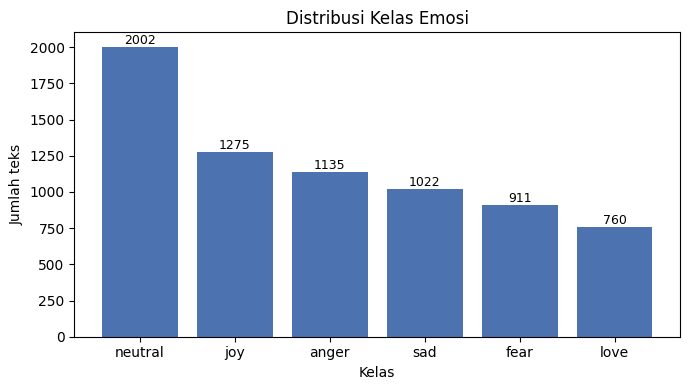

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(dist["label"].astype(str), dist["jumlah"], color="#4C72B0")
for i, v in enumerate(dist["jumlah"]):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi Kelas Emosi")
ax.set_xlabel("Kelas"); ax.set_ylabel("Jumlah teks")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_distribusi_kelas.png", dpi=150)
plt.show()

## Step 4 - Menangani duplikat

In [ ]:
# Normalisasi ringan hanya untuk pengecekan (dataframe asli tdk diubah)
text_norm = df[TEXT_COL].astype(str).str.strip().str.lower()

n_dup_exact = df[[TEXT_COL, LABEL_COL]].duplicated().sum() # teks & label sama persis
n_dup_teks  = text_norm.duplicated().sum() # teks sama (abaikan huruf besar/kecil)

# Teks sama tetapi labelnya beda -> masalah anotasi, penting utk dicatat
label_per_teks = df.assign(_t=text_norm).groupby("_t")[LABEL_COL].nunique()
n_konflik = (label_per_teks > 1).sum()

pd.DataFrame({
    "pemeriksaan": ["Duplikat persis (teks + label)",
                    "Teks duplikat (abaikan huruf besar/kecil & spasi tepi)",
                    "Teks sama tapi label berbeda (konflik)"],
    "jumlah": [n_dup_exact, n_dup_teks, n_konflik],
})

,pemeriksaan,jumlah
0,Duplikat persis (teks + label),52
1,Teks duplikat (abaikan huruf besar/kecil & spasi tepi),63
2,Teks sama tapi label berbeda (konflik),11


In [ ]:
dup_mask = text_norm.duplicated(keep=False)
df[dup_mask].assign(_t=text_norm[dup_mask]).sort_values("_t")[[TEXT_COL, LABEL_COL]].head(10)

,text,label
2445,aaa..senang banget baru bangun udh dapat kabar baikk,joy
3261,aaa..senang banget baru bangun udh dapat kabar baikk,joy
3871,"aku bener bener suka senyumnya mutsuki. yuki senyumnya hangat, mutsuki senyumnya black prince banget . udah gitu aku...",love
3873,"aku bener bener suka senyumnya mutsuki. yuki senyumnya hangat, mutsuki senyumnya black prince banget . udah gitu aku...",love
2228,"allahumma sholli ala sayyidina muhammad semoga hari ini penuh keberkahan untuk kita semua, pekerjaan dan diperlancar...",joy
2386,"allahumma sholli ala sayyidina muhammad semoga hari ini penuh keberkahan untuk kita semua, pekerjaan dan diperlancar...",joy
6874,"apabila kita memiliki kebesaran hati maka kita tdk akan mudah marah, kecewa dan tersinggung.",neutral
6097,"apabila kita memiliki kebesaran hati maka kita tdk akan mudah marah, kecewa dan tersinggung.",neutral
1112,aq dh 5 kali approach..smua ke reject..sedih siot..siap depress..tu la nk ckp takut nk approach dulu x la tp effect ...,anger
646,aq dh 5 kali approach..smua ke reject..sedih siot..siap depress..tu la nk ckp takut nk approach dulu x la tp effect ...,anger


### Step 5 - Distribusi panjang teks

In [ ]:
s = df[TEXT_COL].fillna("").astype(str)
df["n_char"] = s.str.len()
df["n_word"] = s.str.split().str.len()

# Persentil 95/99 berguna nanti untuk menentukan max_len model
df[["n_char", "n_word"]].describe(percentiles=[0.5, 0.95, 0.99]).round(1)

,n_char,n_word
count,7105.0,7105.0
mean,99.2,16.7
std,77.5,12.9
min,4.0,1.0
50%,74.0,13.0
95%,265.0,44.0
99%,278.0,49.0
max,327.0,59.0


In [ ]:
df.groupby(LABEL_COL)["n_word"].agg(["count", "mean", "median", "max"]).round(1)

,count,mean,median,max
label,,,,
anger,1135,17.7,13.0,57
fear,911,12.8,9.0,53
joy,1275,13.2,9.0,58
love,760,21.8,19.0,55
neutral,2002,18.4,15.0,59
sad,1022,16.2,12.0,58


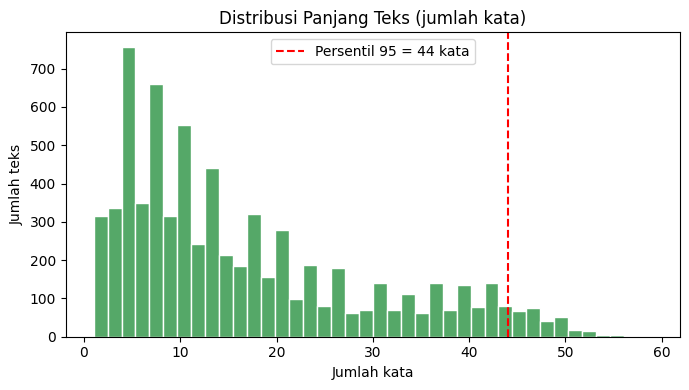

In [ ]:
p95 = df["n_word"].quantile(0.95)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["n_word"], bins=40, color="#55A868", edgecolor="white")
ax.axvline(p95, color="red", linestyle="--", label=f"Persentil 95 = {p95:.0f} kata")
ax.set_title("Distribusi Panjang Teks (jumlah kata)")
ax.set_xlabel("Jumlah kata"); ax.set_ylabel("Jumlah teks")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_distribusi_panjang_teks.png", dpi=150)
plt.show()

### Notes part 1:
- Jumlah data total: 7.105 teks
- Kelas terbanyak | tersedikit: neutral (2.002) | love (760)
- Missing value | teks kosong: 0 | 0
- Duplikat & konflik label: Duplikat persis 52, teks duplikat 63, konflik label 11 teks
- Persentil 95 jumlah kata: 44 kata (acuan `max_len` nanti)